# Where to find pre-trained_models?

1. PyTorch libs: `torchvision.models, torchtext.models, torchaudio.models, torchrec.models` have some pretrained models
2. Huggingface Hub: https://huggingface.co/models, https://huggingface.co/datasets
3. `timm` (PyTorch Image Models) library: https://github.com/rwightman/pytorch-image-models
4. Paperswithcode: https://paperswithcode.com/

In [7]:
import matplotlib.pyplot as plt
import torch
import torchvision

from torch import nn
import torchvision.transforms.v2 as T

from torchinfo import summary

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

# 1. Get Data

## 1.1 下载数据集

In [6]:
# 获取data
!python going_modular/get_data.py

Did not find data\pizza_steak_sushi directory, creating one...
Unzipping pizza, steak, sushi data...


## 1.2 创建dataloaders, 使用 manual creation transform

In [10]:
from going_modular import data_setup
from pathlib import Path

DATA_DIR = Path("data/")
IMAGE_DIR = DATA_DIR / "pizza_steak_sushi"
TRAIN_DIR = IMAGE_DIR / "train"
TEST_DIR = IMAGE_DIR / "test"

BATCH_SIZE = 32

transform = T.Compose([
    T.Resize(size=(224, 224)),
    T.ToImage(),
    T.ToDtype(torch.float32, True),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) 
    # mearn和std通过ImageNet数据集计算得到, 用于transfer learning ImageNet上训练的模型
    # 如果是自己从零开始训练, 应该用自己数据集的mean和std, 而迁移学习必须用预训练模型训练时数据集的mean和std
])

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(
    train_dir= TRAIN_DIR,
    test_dir= TEST_DIR,
    transform=transform,
    batch_size=BATCH_SIZE,
    num_workers=0)
train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x2766bda0830>,
 ['pizza', 'steak', 'sushi'])

## 1.3 创建dataloaders, 使用 auto creation transform

In [12]:
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
weights

EfficientNet_B0_Weights.IMAGENET1K_V1

In [14]:
auto_transform = weights.transforms()
auto_transform

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

In [15]:
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(
    train_dir= TRAIN_DIR,
    test_dir= TEST_DIR,
    transform=auto_transform,
    batch_size=BATCH_SIZE,
    num_workers=0)
train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x2766bd8db50>,
 ['pizza', 'steak', 'sushi'])

# 2. Get pretrained model

## 2.1 下载pretrained_model

In [26]:
model = torchvision.models.efficientnet_b0(weights=weights).to(device)
model

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

## 2.2 使用torchvision查看预训练模型的信息

In [27]:
summary(model=model,
        input_size=(BATCH_SIZE, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names", "depth"]
)

Layer (type (var_name):depth-idx)                                 Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                       [32, 3, 224, 224]    [32, 1000]           --                   True
├─Sequential (features): 1-1                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   True
│    └─Conv2dNormActivation (0): 2-1                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   True
│    │    └─Conv2d (0): 3-1                                       [32, 3, 224, 224]    [32, 32, 112, 112]   864                  True
│    │    └─BatchNorm2d (1): 3-2                                  [32, 32, 112, 112]   [32, 32, 112, 112]   64                   True
│    │    └─SiLU (2): 3-3                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1): 2-2                                 

## 2.3 冻结预训练模型并修改output layer以适配自己的问题

In [28]:
model.features

Sequential(
  (0): Conv2dNormActivation(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): SiLU(inplace=True)
  )
  (1): Sequential(
    (0): MBConv(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): SiLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (activation): SiLU(inplace=True)
          (scale_activation): Sigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(32, 16, kernel_size=(

In [29]:
model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

In [30]:
for param in model.features.parameters():
    param.requires_grad = False # 冻结, 即optimizer不会再更新该参数
    
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features=1280, out_features=len(class_names), bias=True)
).to(device)

In [ ]:
# 再次查看信息
summary(model, 
        input_size=(BATCH_SIZE, 3, 224, 224),
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

# 3. Train Model

In [32]:
from going_modular import engine
from timeit import default_timer as timer

RANDOM_SEED = 42
EPOCHS = 5
torch.manual_seed(RANDOM_SEED)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001)

start = timer()

results = engine.train(model, train_dataloader, test_dataloader, optimizer, loss_fn, EPOCHS, device)

end = timer()
total_time = end - start

print(f"model train time: {total_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0602 | train_acc: 0.4570 | test_loss: 0.8805 | test_acc: 0.7538
Epoch: 2 | train_loss: 0.8532 | train_acc: 0.8164 | test_loss: 0.7683 | test_acc: 0.7737
Epoch: 3 | train_loss: 0.7348 | train_acc: 0.8438 | test_loss: 0.7133 | test_acc: 0.8239
Epoch: 4 | train_loss: 0.6891 | train_acc: 0.7930 | test_loss: 0.6096 | test_acc: 0.9062
Epoch: 5 | train_loss: 0.5976 | train_acc: 0.8164 | test_loss: 0.6026 | test_acc: 0.8864
model train time: 13.202 seconds


In [33]:
results

{'train_loss': [1.0601888075470924,
  0.8532166928052902,
  0.7347909212112427,
  0.6891347840428352,
  0.597606472671032],
 'train_acc': [0.45703125, 0.81640625, 0.84375, 0.79296875, 0.81640625],
 'test_loss': [0.8805383245150248,
  0.7682835261027018,
  0.7132676641146342,
  0.6096368432044983,
  0.6025939782460531],
 'test_acc': [0.7537878787878788,
  0.7736742424242425,
  0.8238636363636364,
  0.90625,
  0.8863636363636364]}

# 4. Evaluate Model

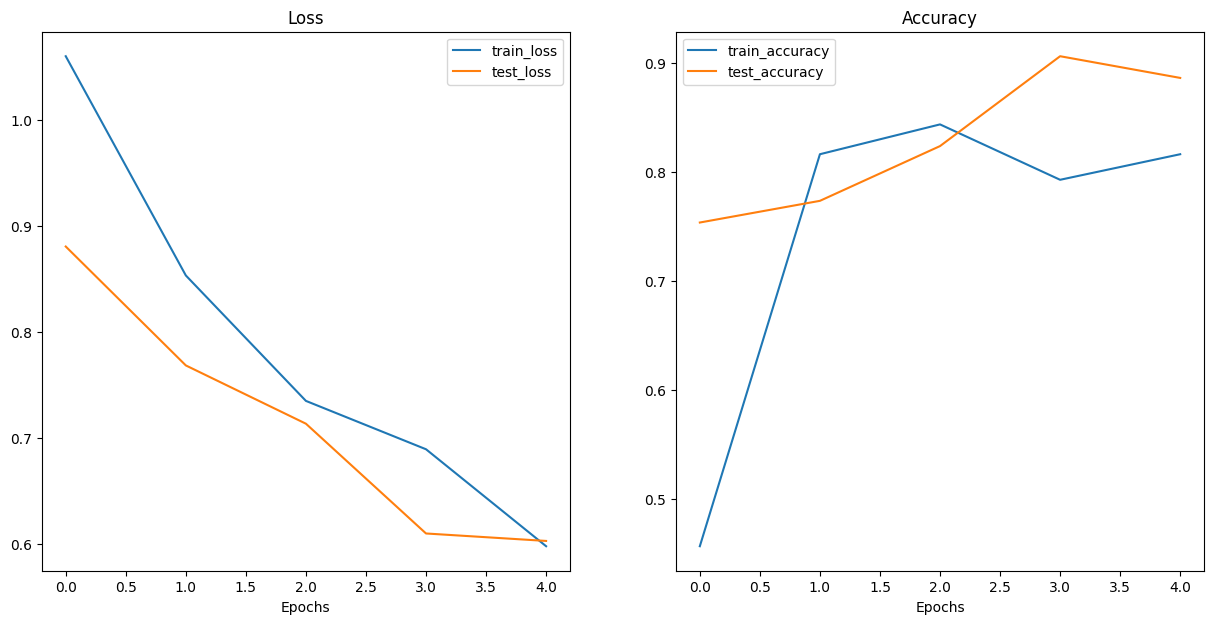

In [34]:
from helper_functions import plot_loss_curves

plot_loss_curves(results)

# 5. Predict Image

## 5.1 创建一个Predict and Plot的方法

In [40]:
from typing import List, Tuple
from torchvision.io import read_image

def pred_and_plot_image(model: torch.nn.Module,
                        image_path: str | Path,
                        class_names: List[str],
                        transform: T.Compose = transform,
                        device: torch.device | str=device):
    raw_image = read_image(str(image_path))
    transformed_image = transform(raw_image)
    
    model = model.to(device)
    model.eval()
    with torch.inference_mode():
        pred_logits = model(transformed_image.unsqueeze(dim=0).to(device))
        pred_probs = torch.softmax(pred_logits, dim=1)
        pred_label = pred_probs.argmax(dim=1)
    
    plt.figure()
    plt.imshow(raw_image.permute(1, 2, 0))
    plt.title(f"Pred: {class_names[pred_label]} | Prob: {pred_probs.max():.3f}")
    plt.axis(False)

## 5.2 Predict随机test image

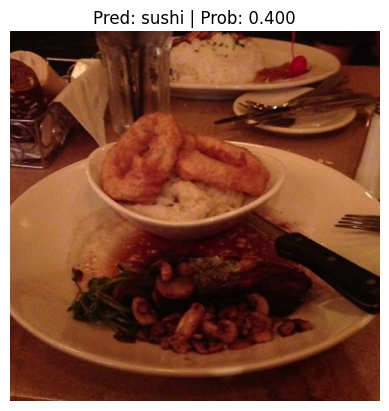

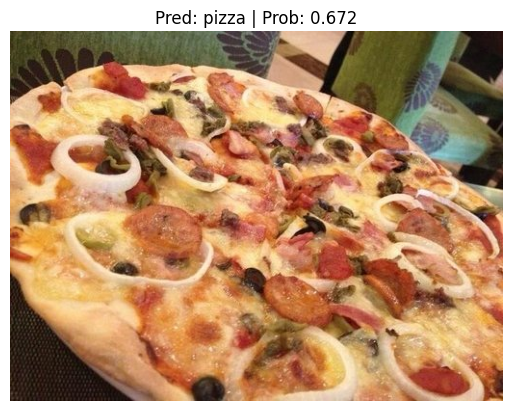

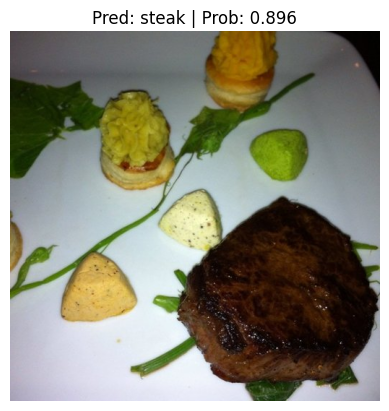

In [41]:
# Get a random list of image paths from test set
import random
num_images_to_plot = 3
test_image_path_list = list(Path(TEST_DIR).glob("*/*.jpg"))
test_image_path_sample = random.sample(population=test_image_path_list,
                                       k=num_images_to_plot)

# Make predictions on and plot the images
for image_path in test_image_path_sample:
    pred_and_plot_image(model=model, 
                        image_path=image_path,
                        class_names=class_names,
                        transform=transform,
                        device=device)

## 5.3 Predict custom image

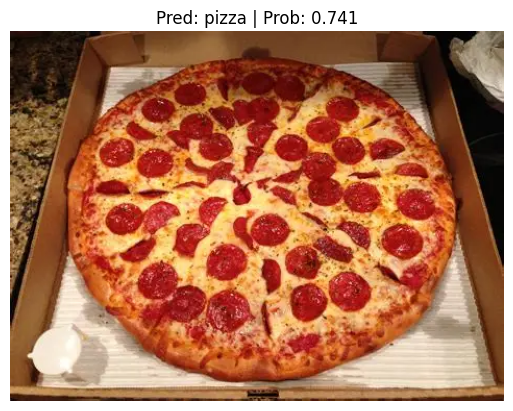

In [42]:

custom_image_path = DATA_DIR / "test_pizza.png"
pred_and_plot_image(model=model, 
                    image_path=custom_image_path,
                    class_names=class_names,
                    transform=transform,
                    device=device)